161 161 161
-5.0 5.0
30.002258745038976 530.0
Array hanno la stessa lunghezza?: True
Hanno valori finiti?: True
L'incertezza è positiva?: True
I valori sono ordinati?: (<module 'numpy' from 'C:\\Users\\emanuele.tedeschi2\\AppData\\Roaming\\Python\\Python313\\site-packages\\numpy\\__init__.py'>, True)


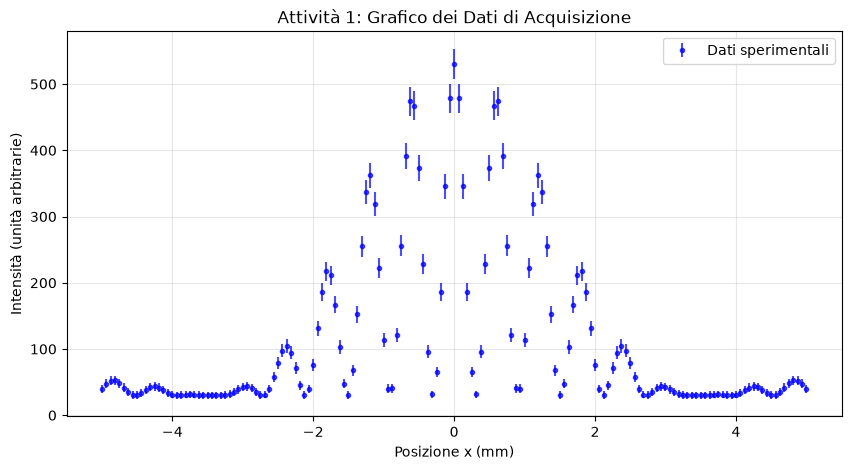

--- Stime Visive (da inserire dopo aver guardato il grafico) ---
1. Fondo stimato (B): [Guarda a che altezza si appiattiscono i lati del grafico]
2. Massimo centrale (I0_circa): [Guarda il picco più alto e sottrai il fondo]
3. Distanza tra le frange: [Guarda lo spazio orizzontale tra due picchi piccoli vicini]
4. Primo minimo dell'inviluppo: [Guarda dove la campana grande 'schiaccia' le frange a zero]


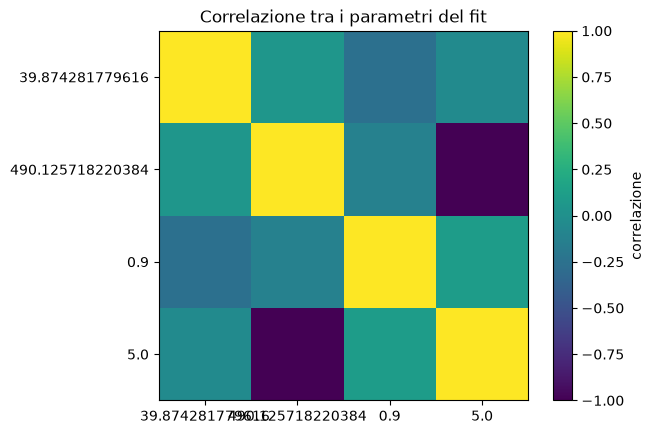

[[ 1.    0.05 -0.26 -0.05]
 [ 0.05  1.   -0.12 -1.  ]
 [-0.26 -0.12  1.    0.11]
 [-0.05 -1.    0.11  1.  ]]
--- Diagnostica del Fit ---
Chi-quadro (chi2): 17822.72
Gradi di libertà (v): 157
Chi-quadro ridotto (chi2_rid): 113.52
p-value: 0.0000e+00


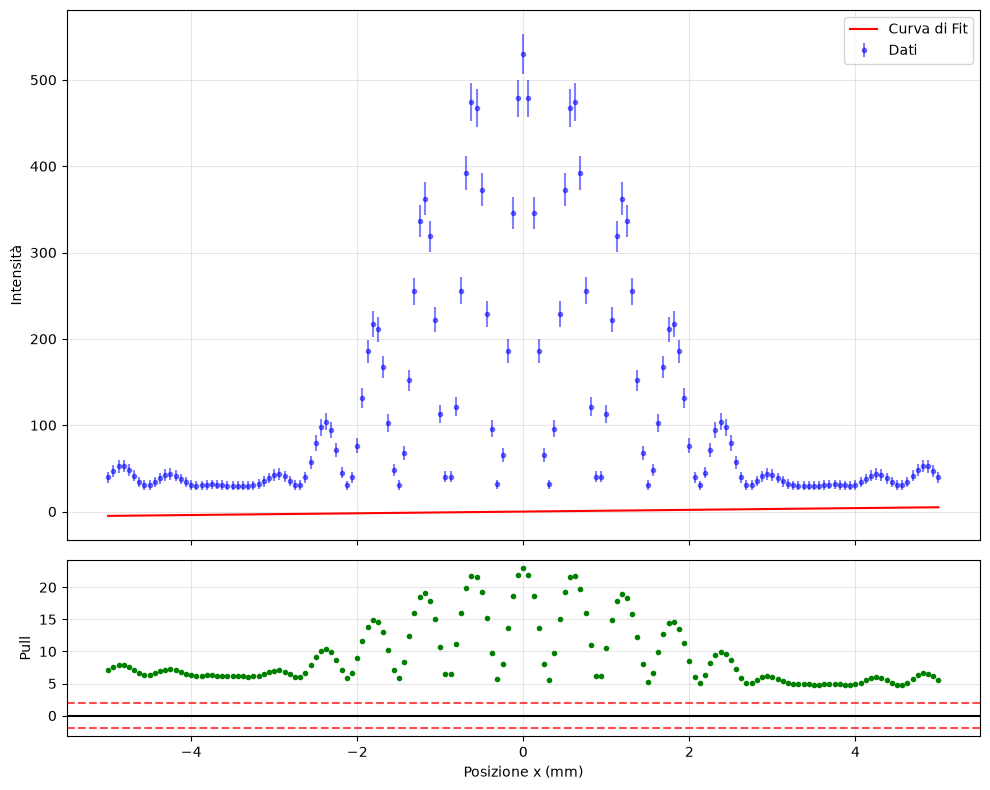

In [83]:
import import_ipynb
from Lab2_1 import data_set

B = 30
I = 500
a = 0.9
d = 5.2
x = np.linspace(-5.0,5.0,161)
y = data_set(B,I,a,d,x)
sigma_y = np.sqrt(y)
print (len(x), len(y), len(sigma_y))
print (np.min(x) , np.max(x))
print (np.min(y), np.max(y))

#Salvo il file con i dati
np.savetxt("dati_fit_interferenza.csv", 
           np.column_stack((x, y, sigma_y)), 
           delimiter=",", 
           header="x, y, sigma_y", 
           comments="")

#Carico i dati dal file che ho appena creato
dati = np.genfromtxt( 
    "dati_fit_interferenza.csv", 
    delimiter=",", 
    names=True 
) 
x = dati["x"] 
y = dati["y"] 
sigma_y = dati["sigma_y"]

#--- Controlli ---
stessa_lunghezza = (len(x) == len(y) == len(sigma_y))
valori_finiti = np.all(np.isfinite(x)) and np.all(np.isfinite(y)) and np.all(np.isfinite(sigma_y))
incertezze_positive = np.all(sigma_y > 0)
posizione_ordinate = np,all(np.diff(x) > 0)

#--- Esito controlli ---
print(f"Array hanno la stessa lunghezza?: {stessa_lunghezza}")
print(f"Hanno valori finiti?: {valori_finiti}")
print(f"L'incertezza è positiva?: {incertezze_positive}")
print(f"I valori sono ordinati?: {posizione_ordinate}")

plt.figure(figsize=(10,5))
plt.errorbar(x, y, yerr=sigma_y, fmt='o', color='blue', markersize=3, alpha=0.7, label='Dati sperimentali')
plt.title('Attività 1: Grafico dei Dati di Acquisizione')
plt.xlabel('Posizione x (mm)')
plt.ylabel('Intensità (unità arbitrarie)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# --- 5. Stime a occhio (Promemoria per l'utente) ---
print("--- Stime Visive (da inserire dopo aver guardato il grafico) ---")
print("1. Fondo stimato (B): [Guarda a che altezza si appiattiscono i lati del grafico]")
print("2. Massimo centrale (I0_circa): [Guarda il picco più alto e sottrai il fondo]")
print("3. Distanza tra le frange: [Guarda lo spazio orizzontale tra due picchi piccoli vicini]")
print("4. Primo minimo dell'inviluppo: [Guarda dove la campana grande 'schiaccia' le frange a zero]")


y_esterni = y[np.abs(x) > 1.2] 
B_guess = np.median(y_esterni)
I_guess = np.max(y) - B_guess
alpha_guess = 0.9
delta_guess = 5.0

#definisco i aprametri iniziali e i bounds
p0 =[B_guess, I_guess, alpha_guess, delta_guess]
lower = [0.0, 0.0, 0.10, 1.0] 
upper = [np.inf, np.inf, 3.0, 12.0]

#ricavo la matrice di covarianza con pcov 
popt, pcov = curve_fit( 
    data_set, x, y, 
    p0=p0, 
    sigma=sigma_y, 
    absolute_sigma=True, 
    bounds=(lower, upper), 
    maxfev=100000 
)

errors = np.sqrt(np.diag(pcov))
corr = pcov / np.outer(errors, errors)

plt.imshow(corr, vmin=-1, vmax=1)
plt.xticks(range(len(p0)), p0)
plt.yticks(range(len(p0)), p0)
plt.colorbar(label="correlazione")
plt.title("Correlazione tra i parametri del fit")
plt.show()

print(np.round(corr, 2))

from scipy.stats import chi2 
y_fit= data_set(x, *popt) #popt è un array con i parametri ottimali della funzione

#calcolo i residui
residui = y - y_fit
pull = residui/sigma_y
chi2_obs= np.sum(pull**2)

N=len(x)
ndf = N - 4
chi2_rid = chi2_obs/ndf
p_value = chi2.sf(chi2_obs, ndf)

print("--- Diagnostica del Fit ---")
print(f"Chi-quadro (chi2): {chi2_obs:.2f}")
print(f"Gradi di libertà (v): {ndf}")
print(f"Chi-quadro ridotto (chi2_rid): {chi2_rid:.2f}")
print(f"p-value: {p_value:.4e}")

# ---  Costruzione della Figura a Due Pannelli ---
# gridspec_kw imposta le proporzioni: il grafico sopra è 3 volte più alto di quello sotto
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, gridspec_kw={'height_ratios': [3, 1]}, figsize=(10, 8))

# Pannello Superiore: Dati e Curva di Fit
ax1.errorbar(x, y, yerr=sigma_y, fmt='o', markersize=3, color='blue', alpha=0.5, label='Dati')
ax1.plot(x, y_fit, color='red', label='Curva di Fit')
ax1.set_ylabel('Intensità')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Pannello Inferiore: Pull
ax2.plot(x, pull, 'o', markersize=3, color='green')
ax2.axhline(0, color='black', linestyle='-') # Indica lo zero
ax2.axhline(2, color='red', linestyle='--', alpha=0.7) # Livello +2
ax2.axhline(-2, color='red', linestyle='--', alpha=0.7) # Livello -2
ax2.set_xlabel('Posizione x (mm)')
ax2.set_ylabel('Pull')
ax2.grid(True, alpha=0.3)

# Mostra il grafico
plt.tight_layout()
plt.show()
